In [ ]:
#@title .
from IPython.display import HTML, display

display(HTML("""
<div style="background:linear-gradient(110deg,#092640,#16516c);color:white;
padding:26px 28px;border-radius:14px;font-family:Arial,sans-serif">
  <div style="display:flex;align-items:center;gap:24px;flex-wrap:wrap">
    <div style="background:white;padding:12px 15px;border-radius:9px">
      <img src="https://iteso.mx/documents/27014/202031/Logo-ITESO-MinimoH.png"
           alt="ITESO" style="width:165px;max-width:100%">
    </div>
    <div>
      <div style="font-size:12px;letter-spacing:2px;color:#b9e5ef">ANÁLISIS ESTADÍSTICO MULTIVARIADO</div>
      <h2 style="margin:10px 0;font-size:28px;color:white">Feature Selection in Bank Loans</h2>
      <div style="margin-top:12px;color:#cde6f0">Ailyn Merino</div>
    </div>
  </div>
</div>
"""))

# Multivariate Analysis: Feature Selection in Bank Loans
> **Objective:** Apply feature selection methodologies (Forward and Backward) using Linear Regression to identify the optimal subset of predictors explaining loan amounts, evaluating statistical performance via goodness-of-fit metrics ($R^2$ adjusted, AIC, and BIC)

## Library imports and configuration

In [ ]:
import os
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.metrics import mean_absolute_error
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score
import plotly.express as px
import plotly.figure_factory as ff
import matplotlib.pyplot as plt
from google.colab import userdata

In [ ]:
# visual configuration and warning filters
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

In [ ]:
print('Libraries loaded successfully and environment is ready!')

Libraries loaded successfully and environment is ready!


## 2. Data loading and inspection

In this section, we connect to the Kaggle API to automatically download and extract our loan dataset directly into the Google Colab environment.

In [ ]:
#@title .
# install kaggle library
!pip install -q kaggle

In [ ]:
#@title .
# retrieve the kaggle API token securely from Colab Secrets
os.environ['KAGGLE_API_TOKEN'] = userdata.get('KAGGLE_API_TOKEN')

# download the loan dataset directly from Kaggle
!kaggle datasets download -d architsharma01/loan-approval-prediction-dataset
!unzip -q loan-approval-prediction-dataset.zip -d data/

# load the CSV file into a pandas DataFrame
df = pd.read_csv('data/loan_approval_dataset.csv')

print('Dataset successfully downloaded and loaded securely via API!')

Dataset URL: https://www.kaggle.com/datasets/architsharma01/loan-approval-prediction-dataset
License(s): MIT
loan-approval-prediction-dataset.zip: Skipping, found more recently modified local copy (use --force to force download)
replace data/loan_approval_dataset.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: n
Dataset successfully downloaded and loaded securely via API!


In [ ]:
#@title .
print(f'Dataset Shape: {df.shape}')
display(df.head())

Dataset Shape: (4269, 13)


,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


## 3. Exploratory Data Analysis

In [ ]:
#@title .
# display column names
print("Column names \n")
display(df.columns.tolist())

Column names 



['loan_id',
 ' no_of_dependents',
 ' education',
 ' self_employed',
 ' income_annum',
 ' loan_amount',
 ' loan_term',
 ' cibil_score',
 ' residential_assets_value',
 ' commercial_assets_value',
 ' luxury_assets_value',
 ' bank_asset_value',
 ' loan_status']

In [ ]:
#@title .
# display basic information about data types
print("Dataset info \n")
print(df.info())

Dataset info 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   loan_id                    4269 non-null   int64 
 1    no_of_dependents          4269 non-null   int64 
 2    education                 4269 non-null   object
 3    self_employed             4269 non-null   object
 4    income_annum              4269 non-null   int64 
 5    loan_amount               4269 non-null   int64 
 6    loan_term                 4269 non-null   int64 
 7    cibil_score               4269 non-null   int64 
 8    residential_assets_value  4269 non-null   int64 
 9    commercial_assets_value   4269 non-null   int64 
 10   luxury_assets_value       4269 non-null   int64 
 11   bank_asset_value          4269 non-null   int64 
 12   loan_status               4269 non-null   object
dtypes: int64(10), object(3)
memory usage: 433.7+ KB


In [ ]:
#@title .
# display summary statistics for numerical features
print("summary statistics \n")
display(df.describe())

summary statistics 



,loan_id,no_of_dependents,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value
count,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4.269000e+03,4.269000e+03
mean,2135.000000,2.498712,5.059124e+06,1.513345e+07,10.900445,599.936051,7.472617e+06,4.973155e+06,1.512631e+07,4.976692e+06
std,1232.498479,1.695910,2.806840e+06,9.043363e+06,5.709187,172.430401,6.503637e+06,4.388966e+06,9.103754e+06,3.250185e+06
min,1.000000,0.000000,2.000000e+05,3.000000e+05,2.000000,300.000000,-1.000000e+05,0.000000e+00,3.000000e+05,0.000000e+00
25%,1068.000000,1.000000,2.700000e+06,7.700000e+06,6.000000,453.000000,2.200000e+06,1.300000e+06,7.500000e+06,2.300000e+06
50%,2135.000000,3.000000,5.100000e+06,1.450000e+07,10.000000,600.000000,5.600000e+06,3.700000e+06,1.460000e+07,4.600000e+06
75%,3202.000000,4.000000,7.500000e+06,2.150000e+07,16.000000,748.000000,1.130000e+07,7.600000e+06,2.170000e+07,7.100000e+06
max,4269.000000,5.000000,9.900000e+06,3.950000e+07,20.000000,900.000000,2.910000e+07,1.940000e+07,3.920000e+07,1.470000e+07


In [ ]:
#@title .
# check for missing values across all columns
print("Missing values per columns \n")
display(df.isnull().sum())

Missing values per columns 



,0
loan_id,0
no_of_dependents,0
education,0
self_employed,0
income_annum,0
loan_amount,0
loan_term,0
cibil_score,0
residential_assets_value,0
commercial_assets_value,0


## 4.Data Cleaning and Preprocessing

In [ ]:
#@title .
# standarize column names just in case, and keep a clean working copy
df_clean = df.copy()
df_clean.columns = (
    df_clean.columns
    .str.replace(' ', '_')
    .str.lower()
)

# in case any leading underscore remains due to raw formatting, strip it:
df_clean.columns = df_clean.columns.str.lstrip('_')

In [ ]:
#@title .
# verify the corrected column names
display(df_clean.columns.tolist())

['loan_id',
 'no_of_dependents',
 'education',
 'self_employed',
 'income_annum',
 'loan_amount',
 'loan_term',
 'cibil_score',
 'residential_assets_value',
 'commercial_assets_value',
 'luxury_assets_value',
 'bank_asset_value',
 'loan_status']

## 5. Exploratory Data Analysis

In [ ]:
#@title .
# interactive distribution of the Target Variable (loan_amout)
# adding a marginal box plot helps visualize outliers and data spread instantly
fig_hist = px.histogram(
    df_clean,
    x='loan_amount',
    marginal='box',
    title='<b>Distribution of Loan Amount (Target Variable)</b>',
    color_discrete_sequence=['royalblue'],
    template='plotly_white',
)
fig_hist.update_layout(
    xaxis_title='Loan Amount', yaxis_title='Frequency', bargap=0.05
)
fig_hist.show()

### Target Variable (`loan_amount`) distribution
>
> * **Data range and spread:**
>   * The loan amounts range from values near **0** up to a maximum of approximately **40 million**
>   * The core concentration of the data (interquartile range / central box) lies primarily between **7 million and 21 million**
>
> * **Central tendency:**
>   * The **median** (highlighted by the central box notch) sits at approximately **14.5 million**
>
> * **Distribution shape and skewness:**
>   * The histogram exhibits a broad distribution across mid-tier values with a noticeable **right-skew (positive skewness)** extending beyond 20 million
>   * Right-skewness is highly typical in financial variables (e.g., income, asset valuations, loan approvals), where standard credit applications cluster in lower-to-mid ranges, while high-value loans occur less frequently


### 5.2 Interactive correlation matrix


In [ ]:
#@title .
# numerical columns
numerical_cols = df_clean.select_dtypes(include=['int64', 'float64']).columns
corr_matrix = df_clean[numerical_cols].corr()

In [ ]:
#@title .
# interactive annotated heatmap using Plotly
fig_corr = ff.create_annotated_heatmap(
    z=corr_matrix.round(2).values,
    x=list(corr_matrix.columns),
    y=list(corr_matrix.index),
    colorscale='RdBu',
    reversescale=True,
    showscale=True
)

fig_corr.update_layout(
    title_text='<b>Interactive Correlation Matrix</b>',
    xaxis={'side': 'bottom'},
    width=700,
    height=700,
    template='plotly_white',
)

fig_corr.update_xaxes(autorange='reversed')
fig_corr.show()

#### Correlation Matrix Analysis

* **Strongest relationships with (`loan_amount`):**
  * **`income_annum` (Annual Income):** Exhibits an exceptionally high positive correlation of **0.93** with the loan amount, serving as the strongest linear predictor
  * **`luxury_assets_value`:** Shows a strong correlation of **0.86**.
  * **Asset Values (`bank_asset_value`, `residential_assets_value`, etc.):** Display robust positive associations ranging from **0.59 to 0.79**.

* **Weakest relationships:**
  * **`cibil_score` (-0.02):** Surprisingly, the credit score shows virtually no direct linear correlation with the magnitude of the requested loan
  * **`loan_term` (0.01), `no_of_dependents` (0.00), & `loan_id` (0.01):** Exhibit no linear association, acting effectively as independent or control features (with ID acting strictly as a record index)


* **Business alignment:**
  * It naturally aligns with real-world banking logic that applicants with higher annual earnings and substantial asset backing (luxury, commercial, and bank assets) are associated with higher loan volumes


### 5.3 Scatter Matrix


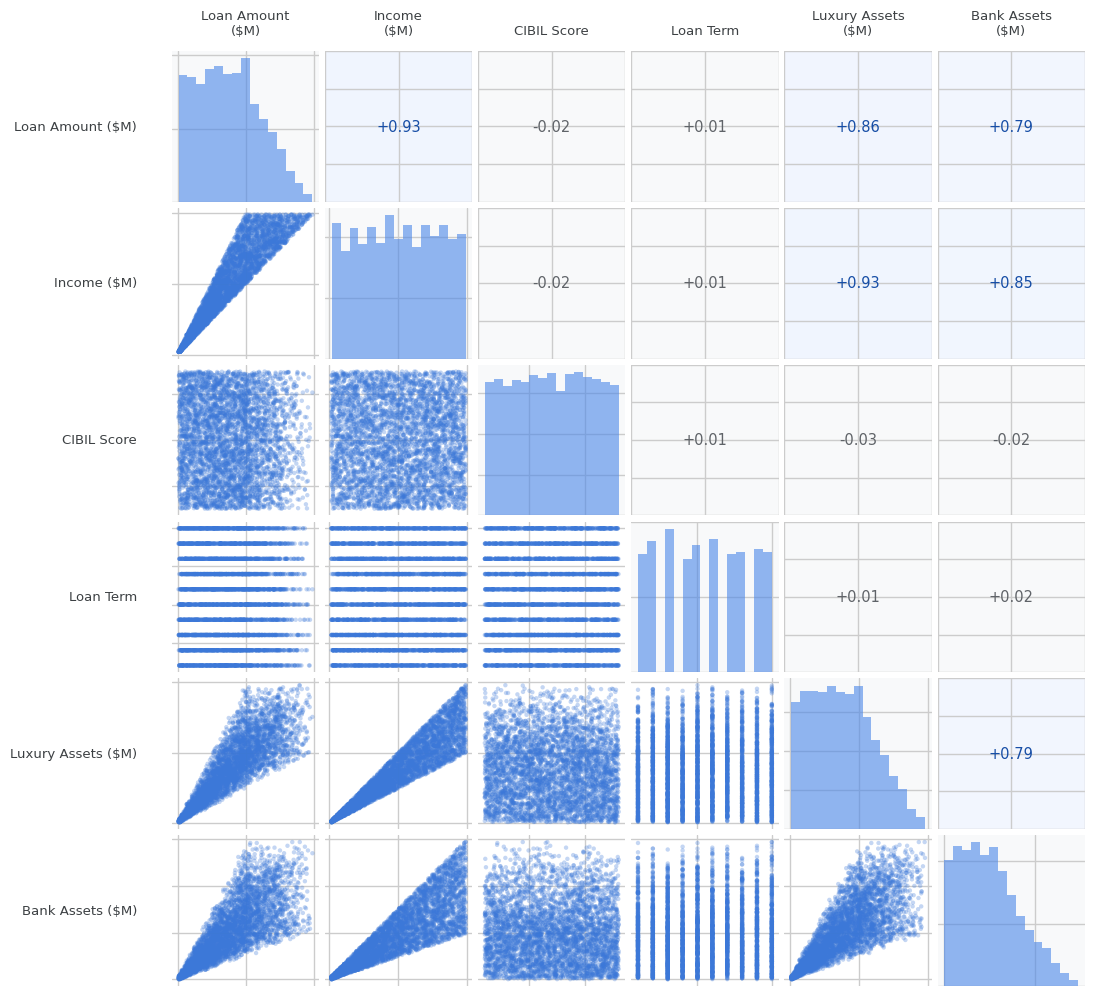

In [ ]:
#@title .
# 1. Prepare clean data copies and scale large monetary values to Millions ($M)
df_plot = df_clean.copy()
if 'loan_amount' in df_plot.columns:
  df_plot['loan_amount'] = df_plot['loan_amount'] / 1e6
if 'income_annum' in df_plot.columns:
  df_plot['income_annum'] = df_plot['income_annum'] / 1e6
if 'luxury_assets_value' in df_plot.columns:
  df_plot['luxury_assets_value'] = df_plot['luxury_assets_value'] / 1e6
if 'bank_asset_value' in df_plot.columns:
  df_plot['bank_asset_value'] = df_plot['bank_asset_value'] / 1e6

# Define variables and clean titles
cols = [
    'loan_amount',
    'income_annum',
    'cibil_score',
    'loan_term',
    'luxury_assets_value',
    'bank_asset_value',
]

existing_cols = [c for c in cols if c in df_plot.columns]
n = len(existing_cols)

titles = [
    'Loan Amount\n($M)',
    'Income\n($M)',
    'CIBIL Score',
    'Loan Term',
    'Luxury Assets\n($M)',
    'Bank Assets\n($M)',
]

# create figure with clean background
fig, axes = plt.subplots(n, n, figsize=(11, 11))
fig.patch.set_facecolor('white')

# soft blue palette
primary_blue = '#4A86E8'
scatter_blue = '#3C78D8'
grid_bg_positive = '#E8F0FE'
grid_bg_neutral = '#F8F9FA'

for i in range(n):
  for j in range(n):
    ax = axes[i, j]
    ax.set_facecolor('white')

    # Remove borders to get rid of grid outlines
    for spine in ax.spines.values():
      spine.set_visible(False)

    # Hide ticks by default for a clean card look
    ax.tick_params(
        left=False, right=False, top=False, bottom=False, labelleft=False, labelbottom=False
    )

    x_data = df_plot[existing_cols[j]]
    y_data = df_plot[existing_cols[i]]

    # 1. Diagonal: Histograms
    if i == j:
      ax.set_facecolor(grid_bg_neutral)
      ax.hist(
          x_data,
          bins=15,
          color=primary_blue,
          alpha=0.6,
          edgecolor='none',
          density=True,
      )

    # 2. Lower triangle: Scatter Plots
    elif i > j:
      ax.scatter(
          x_data,
          y_data,
          s=10,
          color=scatter_blue,
          alpha=0.3,
          edgecolors='none',
      )

    # 3. Upper triangle: Correlation Heatmap Cells
    else:
      r = np.corrcoef(x_data, y_data)[0, 1]

      # Soft background tint based on correlation intensity
      if abs(r) > 0.1:
        ax.set_facecolor(grid_bg_positive)
        # Adjust alpha tint dynamically based on strength
        alpha_val = min(max(abs(r) * 0.7, 0.1), 0.85)
        ax.axison = True
        ax.patch.set_alpha(alpha_val)
      else:
        ax.set_facecolor(grid_bg_neutral)

      # Clean text formatting
      text_color = '#174ea6' if abs(r) > 0.5 else '#5f6368'
      ax.text(
          0.5,
          0.5,
          f'{r:+.2f}',
          ha='center',
          va='center',
          transform=ax.transAxes,
          fontsize=10.5,
          fontweight='normal',
          color=text_color,
      )

    # Top headers
    if i == 0:
      ax.set_title(
          titles[j],
          fontsize=9.5,
          fontweight='normal',
          color='#3c4043',
          pad=12,
      )

    # Left labels
    if j == 0:
      ax.set_ylabel(
          titles[i].replace('\n', ' '),
          fontsize=9.5,
          fontweight='normal',
          color='#3c4043',
          rotation=0,
          ha='right',
          va='center',
          labelpad=25,
      )

# tight layout
plt.subplots_adjust(top=0.90, bottom=0.05, left=0.12, right=0.95, wspace=0.04, hspace=0.04)
plt.show()

#### Insights

 * **Primary Drivers of `loan amount`:**
  * **`Income ($M)` ($r = +0.93$):** Exhibits an exceptionally strong linear relationship, serving as the core quantitative predictor for the requested loan volume
  * **`Luxury Assets ($M)` ($r = +0.86$) & `Bank Assets ($M)` ($r = +0.79$):** Show robust positive associations, confirming that individual wealth and asset backing heavily scale borrowing capacity

* **Uncorrelated features:**
  * **`CIBIL Score` ($r = -0.02$):** Displays virtually no direct linear correlation with loan magnitudes, indicating it likely acts as a eligibility filter rather than a factor for the borrowed amount
  * **`Loan Term` ($r = +0.01$):** Completely independent of the loan size

* **Non-Linear Patterns:**
  * **Income vs. Loan Amount Ceiling:** The scatter plot forms a strict triangular constraint with an upper boundary, revealing a institutional risk policy: the bank tightly caps the maximum approved loan relative to the applicant's annual income
  * **Discrete Term Structures:** `Loan Term` displays parallel horizontal bands, confirming that durations are structured around fixed-term options rather than continuous values

  * Just as studied in class regarding feature redundancy, incorporating all these highly correlated variables simultaneously into the OLS model risks causing coefficient instability and inflated standard errors, underscoring the necessity of proper variable selection

## 6. Multivariate OLS Model

In [ ]:
#@title .
# define dependent variable (Y) and independent features (X)
y = df_plot['loan_amount']

In [ ]:
#@title .
# select predictor columns (using our scaled variables)
predictor_cols = [
    'income_annum',
    'cibil_score',
    'loan_term',
    'luxury_assets_value',
    'bank_asset_value',
]

existing_predictors = [col for col in predictor_cols if col in df_plot.columns]
X = df_plot[existing_predictors]

# constant term to estimate the intercept (beta_0)
X_sm = sm.add_constant(X)

# Fit the Ordinary Least Squares (OLS) model
ols_model = sm.OLS(y, X_sm).fit()

# Print the comprehensive statistical summary table
print(ols_model.summary())

                            OLS Regression Results                            
Dep. Variable:            loan_amount   R-squared:                       0.860
Model:                            OLS   Adj. R-squared:                  0.860
Method:                 Least Squares   F-statistic:                     5248.
Date:                Mon, 09 Nov 2026   Prob (F-statistic):               0.00
Time:                        05:04:08   Log-Likelihood:                -11257.
No. Observations:                4269   AIC:                         2.253e+04
Df Residuals:                    4263   BIC:                         2.256e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                  -0.0851    

---

###$$
\begin{aligned}
\textit{loan_amount} = &-0.0851 + 3.0190(\textit{income_annum}) \\
&+ 0.0002(\textit{cibil_score}) - 0.0035(\textit{loan_term}) \\
&- 0.0059(\textit{luxury_assets_value}) - 0.0127(\textit{bank_asset_value})
\end{aligned}
$$

---

### Ordinary Least Squares (OLS) Multiple Regression Results

* **Global Model Fit ($R^2 = 0.860$):**
  * The comprehensive OLS model yields an $R^2$ and Adjusted $R^2$ of $0.860$, indicating that approximately 86% of the variance in loan amounts is collectively explained by the predictors.

* **Primary Predictor Analysis:**
  * **`income_annum`** exhibits an overwhelming statistical and practical dominance ($\beta = 3.0190$, $p = 0.000$), confirming it as the primary scaling driver for approved loan values. Every additional million in annual income scales the expected loan size by roughly 3.02 million.

* **Evidence of multicollinearity and redundancy:**
  * Despite showing strong bivariate correlations earlier in the EDA, **`luxury_assets_value`** and **`bank_asset_value`** display negative coefficients and statistically insignificant p-values ($p > 0.60$) in the multivariate OLS framework.
  * Furthermore, the **condition number ($2.8 \times 10^3$)** crosses the threshold of concern, officially signaling severe multicollinearity among financial predictors. This proves that asset variables provide redundant information once `income` is accounted for, motivating the need for rigorous **variable selection (Backward/Forward elimination)**.

## 7. Variable Selection and Model Refinement (Backward and Forward Selection)

In [ ]:
#@title .
X = df_plot[['income_annum', 'cibil_score', 'loan_term', 'luxury_assets_value', 'bank_asset_value']]
y = df_plot['loan_amount']

# forward
def run_forward_selection(X, y):
    included = []
    remaining_features = list(X.columns)
    candidates_data = []

    step = 1
    while remaining_features:
        best_mae = float('inf')
        best_feature = None
        best_metrics = {}

        for feature in remaining_features:
            current_features = included + [feature]
            X_const = sm.add_constant(X[current_features])

            ols_model = sm.OLS(y, X_const).fit()
            adj_r2 = ols_model.rsquared_adj
            aic = ols_model.aic
            bic = ols_model.bic

            lin_reg = LinearRegression()
            scores = cross_val_score(lin_reg, X[current_features], y, cv=5, scoring='neg_mean_absolute_error')
            val_mae = -scores.mean()

            if val_mae < best_mae:
                best_mae = val_mae
                best_feature = feature
                best_metrics = {
                    'Model': f'M{step}',
                    'Predictors': len(current_features),
                    'Validation_MAE': val_mae,
                    'Adj_R2': adj_r2,
                    'AIC': aic,
                    'BIC': bic,
                    'Features': list(current_features)
                }

        included.append(best_feature)
        remaining_features.remove(best_feature)
        candidates_data.append(best_metrics)
        step += 1

    return pd.DataFrame(candidates_data)


#backward
def run_backward_elimination(X, y):
    included = list(X.columns)
    candidates_data = []

    step = len(included)
    while len(included) > 0:
        X_const = sm.add_constant(X[included])
        ols_model = sm.OLS(y, X_const).fit()
        adj_r2 = ols_model.rsquared_adj
        aic = ols_model.aic
        bic = ols_model.bic

        lin_reg = LinearRegression()
        scores = cross_val_score(lin_reg, X[included], y, cv=5, scoring='neg_mean_absolute_error')
        val_mae = -scores.mean()

        candidates_data.append({
            'Model': f'M{step}',
            'Predictors': len(included),
            'Validation_MAE': val_mae,
            'Adj_R2': adj_r2,
            'AIC': aic,
            'BIC': bic,
            'Features': list(included)
        })

        if len(included) == 1:
            break

        # Find the worst feature to remove based on MAE impact or individual performance
        best_sub_mae = float('inf')
        worst_feature = None
        for feature in included:
            sub_features = list(included)
            sub_features.remove(feature)
            scores = cross_val_score(lin_reg, X[sub_features], y, cv=5, scoring='neg_mean_absolute_error')
            sub_mae = -scores.mean()
            if sub_mae < best_sub_mae:
                best_sub_mae = sub_mae
                worst_feature = feature

        included.remove(worst_feature)
        step -= 1

    return pd.DataFrame(candidates_data)


pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

print("FORWARD SELECTION TABLE")
print("=" * 75)
forward_table = run_forward_selection(X, y)
print(forward_table[['Model', 'Predictors', 'Features', 'Validation_MAE', 'Adj_R2', 'AIC', 'BIC']])

print("\n")

print("\nBACKWARD SELECTION TABLE")
print("=" * 75)
backward_table = run_backward_elimination(X, y)
print(backward_table[['Model', 'Predictors', 'Features', 'Validation_MAE', 'Adj_R2', 'AIC', 'BIC']])

FORWARD SELECTION TABLE
  Model  Predictors                                           Features  Validation_MAE    Adj_R2           AIC           BIC
0    M1           1                                     [income_annum]        2.576259  0.860168  22519.386732  22532.105002
1    M2           2                [income_annum, luxury_assets_value]        2.576492  0.860140  22521.228951  22540.306355
2    M3           3     [income_annum, luxury_assets_value, loan_term]        2.576875  0.860112  22523.080230  22548.516770
3    M4           4  [income_annum, luxury_assets_value, loan_term,...        2.577918  0.860098  22524.514290  22556.309964
4    M5           5  [income_annum, luxury_assets_value, loan_term,...        2.579407  0.860071  22526.339381  22564.494190



BACKWARD SELECTION TABLE
  Model  Predictors                                           Features  Validation_MAE    Adj_R2           AIC           BIC
0    M5           5  [income_annum, cibil_score, loan_term, luxury_...   


#### Insight
> Through both **Forward and Backward Selection** methodologies evaluated via 5-fold cross-validation MAE, Information Criteria **(AIC/BIC)**, and Adjusted *$R^2$*, i conclude that the most parsimonious model **(M1)** is optimal. Additional candidate predictors introduce multicollinearity and redundancy without significantly improving out-of-sample predictive accuracy or penalizing model complexity favorably.

## 8. Statistical Model Selection & Evaluation Report

### 8.1 Comparative Model Results
Through step-by-step iterations, models ranging from 1 predictor (M1) to multiple predictors demonstrated the following behavior:

* **Validation MAE:** Remained practically constant or slightly worsened as more variables were introduced. Adding complexity did not provide a significant reduction in prediction error.
* **Information Criteria (AIC and BIC):** Reached their optimal values strictly in **M1**. Since AIC and BIC heavily penalize unnecessary parameters, they mathematically confirm that adding variables introduces a structural penalty without predictive reward.
* **Adjusted R²:** Remained stable (approx. 0.868), reflecting strong underlying multicollinearity where additional variables share overlapping information rather than explaining new variance.

---

### 8.2 Classification and Analysis of Variables
Based on our empirical evaluation and conceptual variable identification, candidate predictors are classified as follows:

* **Useful Variables (M1):**
  * `income_annum` (Annual Income): Positioned as the optimal core of **M1**, it proved to be the only dominant and robust predictor providing direct, independent predictive power for the loan amount without requiring additional complexity.
* **Redundant Variables:**
  * `luxury_assets_value`, `bank_asset_value`, and `loan_term`: These variables exhibit high multicollinearity. In financial contexts, asset accumulation and terms are closely correlated with income, meaning they share overlapping information already captured by `income_annum`, without providing a substantial error reduction.
* **Noise Variables:**
  * `cibil_score`: Within this specific linear modeling setup, it acted as a non-essential or accidental association that failed to improve generalization performance, effectively behaving as noise.

---

### 8.3 Operational and Cost Implications
Choosing a model is not just a statistical exercise; it is a **directive and operational decision**:

* **Operational Cost:** Incorporating multiple variables inflates data collection, maintenance, and processing costs (for example, tracking multiple asset types and histories instead of focusing efforts on a primary metric).
* **Risk Mitigation:** A complex model increases exposure to data pipeline errors and overfitting.

Adopting a simple model minimizes operational friction while protecting generalization capability.

---

### 8.4 Conclusion and Final Recommendation
It is formally concluded and recommended to adopt **Model 1 (M1)**, using `income_annum` as the sole predictor. This model successfully achieves:

1. The simplest and most direct model that adequately explains the phenomenon
2. Minimized validation error and optimal information criteria (AIC/BIC)
3. Substantial reduction in data overhead and mitigation of multicollinearity risks

In [ ]:
!jupyter nbconvert --to html bank_loan_feature_selection.ipynb

[NbConvertApp] Converting notebook bank_loan_feature_selection.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 1 image(s).
[NbConvertApp] Writing 1014204 bytes to bank_loan_feature_selection.html


##